In [11]:
!pip -q install numpy pandas scipy matplotlib pytest
print("STARTRACE AI environment ready!")


STARTRACE AI environment ready!


In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import median_filter
from itertools import combinations

print("Imports successful.")


Imports successful.


In [13]:

def make_light_curve(
    period=3.0,
    duration=0.12,
    depth=0.02,
    noise=0.001,
    seed=42,
):
    rng = np.random.default_rng(seed)
    time = np.arange(0, 30, 0.05)
    flux = 1.0 + rng.normal(0, noise, len(time))

    if period is not None:
        phase = np.mod(time, period)
        in_transit = (
            (phase < duration / 2)
            | (phase > period - duration / 2)
        )
        flux[in_transit] -= depth

    return pd.DataFrame({"time": time, "flux": flux})


data = make_light_curve()

print("Number of observations:", len(data))
display(data.head())


Number of observations: 600


,time,flux
0,0.00,0.980305
1,0.05,0.978960
2,0.10,1.000750
3,0.15,1.000941
4,0.20,0.998049


In [14]:

def make_light_curve(
    period=3.0,
    duration=0.12,
    depth=0.02,
    noise=0.001,
    seed=42,
):
    rng = np.random.default_rng(seed)
    time = np.arange(0, 30, 0.05)
    flux = 1.0 + rng.normal(0, noise, len(time))

    if period is not None:
        phase = np.mod(time, period)
        in_transit = (
            (phase < duration / 2)
            | (phase > period - duration / 2)
        )
        flux[in_transit] -= depth

    return pd.DataFrame({"time": time, "flux": flux})


data = make_light_curve()

print("Number of observations:", len(data))
display(data.head())


Number of observations: 600


,time,flux
0,0.00,0.980305
1,0.05,0.978960
2,0.10,1.000750
3,0.15,1.000941
4,0.20,0.998049


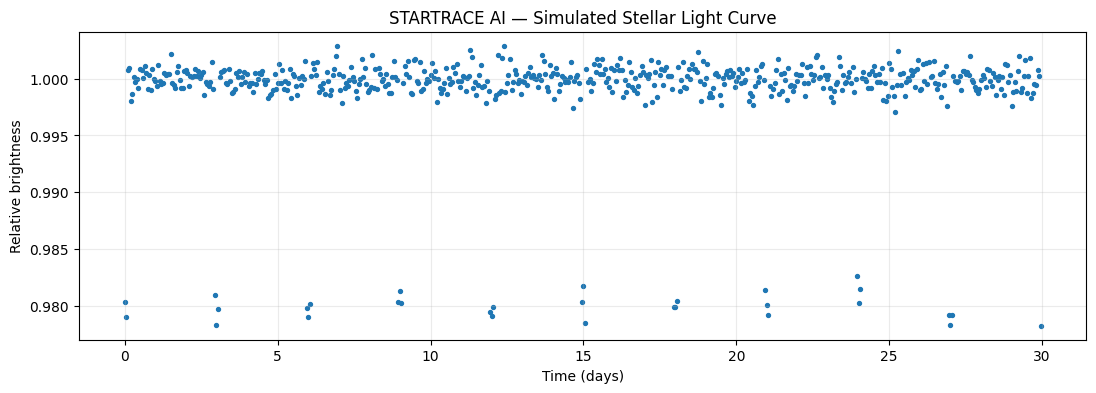

In [15]:

plt.figure(figsize=(13, 4))
plt.scatter(data["time"], data["flux"], s=8)
plt.xlabel("Time (days)")
plt.ylabel("Relative brightness")
plt.title("STARTRACE AI — Simulated Stellar Light Curve")
plt.grid(alpha=0.25)
plt.show()


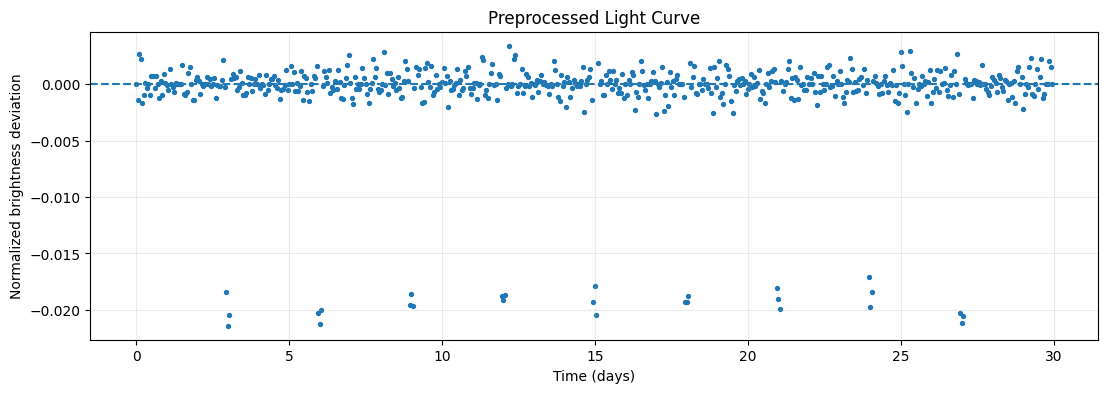

In [16]:

def preprocess_light_curve(data, time_col="time", flux_col="flux", window=9):
    if time_col not in data.columns or flux_col not in data.columns:
        raise ValueError(
            f"CSV must contain '{time_col}' and '{flux_col}' columns."
        )

    df = data[[time_col, flux_col]].copy()
    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")
    df[flux_col] = pd.to_numeric(df[flux_col], errors="coerce")

    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df.sort_values(time_col).drop_duplicates(time_col)

    if len(df) < 10:
        raise ValueError("At least 10 valid observations are required.")
    if (df[flux_col] <= 0).any():
        raise ValueError("Flux values must be positive.")

    values = df[flux_col].to_numpy(dtype=float)

    window = max(3, int(window))
    if window % 2 == 0:
        window += 1
    window = min(window, len(values) if len(values) % 2 else len(values) - 1)

    trend = median_filter(values, size=window, mode="nearest")
    trend = np.where(trend <= 0, np.nanmedian(values), trend)

    df["trend"] = trend
    df["relative_flux"] = values / trend - 1.0

    return df.reset_index(drop=True)


curve = preprocess_light_curve(data)

plt.figure(figsize=(13, 4))
plt.scatter(curve["time"], curve["relative_flux"], s=8)
plt.axhline(0, linestyle="--")
plt.xlabel("Time (days)")
plt.ylabel("Normalized brightness deviation")
plt.title("Preprocessed Light Curve")
plt.grid(alpha=0.25)
plt.show()


In [17]:

def robust_sigma(values):
    median = np.median(values)
    sigma = 1.4826 * np.median(np.abs(values - median))

    if not np.isfinite(sigma) or sigma < 1e-10:
        sigma = float(np.std(values))

    return max(float(sigma), 1e-8)


def detect_dips(curve, sigma_threshold=3.0, min_depth=0.001):
    t = curve["time"].to_numpy(dtype=float)
    y = curve["relative_flux"].to_numpy(dtype=float)
    noise = robust_sigma(y)

    threshold = min(-sigma_threshold * noise, -min_depth)
    mask = y < threshold

    starts = np.flatnonzero(mask & ~np.r_[False, mask[:-1]])
    ends = np.flatnonzero(mask & ~np.r_[mask[1:], False])

    events = []

    for start, end in zip(starts, ends):
        segment = y[start:end + 1]
        center_index = start + int(np.argmin(segment))

        events.append({
            "time": float(t[center_index]),
            "depth": float(max(0.0, -np.median(segment))),
            "points": int(end - start + 1),
            "start_time": float(t[start]),
            "end_time": float(t[end]),
        })

    return events, noise


events, noise = detect_dips(curve)

print("Estimated noise:", round(noise, 6))
print("Detected dip events:", len(events))
display(pd.DataFrame(events).head(10))


Estimated noise: 0.000907
Detected dip events: 9


,time,depth,points,start_time,end_time
0,3.00,0.020494,3,2.95,3.05
1,6.00,0.020261,3,5.95,6.05
2,9.05,0.019598,3,8.95,9.05
3,12.00,0.018805,3,11.95,12.05
4,15.05,0.019307,3,14.95,15.05
5,18.00,0.019301,3,17.95,18.05
6,21.05,0.019037,3,20.95,21.05
7,24.00,0.018400,3,23.95,24.05
8,27.00,0.020578,3,26.95,27.05


In [18]:

def estimate_period(event_times, cadence, min_period=0.5, max_period=None):
    times = np.sort(np.asarray(event_times, dtype=float))

    if len(times) < 2:
        return None, 0.0, None

    span = float(times[-1] - times[0])

    if max_period is None:
        max_period = span / 2

    if max_period < min_period:
        return None, 0.0, None

    candidates = set()

    for a, b in combinations(times, 2):
        difference = float(b - a)

        for divisor in range(1, 6):
            p = difference / divisor

            if min_period <= p <= max_period:
                candidates.add(round(p, 8))

    if not candidates:
        return None, 0.0, None

    best_period = None
    best_consistency = 0.0
    best_objective = -1.0
    best_epoch = None

    for period in candidates:
        phases = np.mod(times - times[0], period)
        distances = np.minimum(phases, period - phases)

        tolerance = max(2 * cadence, 0.03 * period)
        matched = distances <= tolerance
        consistency = float(np.mean(matched))

        objective = consistency * (
            0.8 + 0.2 * len(times) / (1 + period)
        )

        if objective > best_objective:
            best_objective = objective
            best_period = period
            best_consistency = consistency
            best_epoch = float(times[0])

    return best_period, best_consistency, best_epoch


event_times = [event["time"] for event in events]
cadence = float(np.median(np.diff(curve["time"].to_numpy())))

period, consistency, epoch = estimate_period(
    event_times,
    cadence,
    min_period=1.0,
    max_period=8.0,
)

print("Estimated period (days):", period)
print("Event consistency:", round(consistency, 3))
print("Reference epoch (days):", epoch)


Estimated period (days): 1.0
Event consistency: 1.0
Reference epoch (days): 3.0


In [19]:

depth = (
    float(np.median([event["depth"] for event in events]))
    if events else 0.0
)

depth_percent = depth * 100 if events else None

event_factor = min(len(events) / 3.0, 1.0)
repeat_factor = consistency if period is not None else 0.0
signal_to_noise = depth / noise if noise > 0 else 0.0
strength_factor = min(signal_to_noise / 8.0, 1.0)

score = round(
    100 * (
        0.40 * event_factor
        + 0.35 * repeat_factor
        + 0.25 * strength_factor
    ),
    1,
)

if len(events) >= 2 and period is not None and consistency >= 0.6:
    status = "periodic_candidate"
elif len(events) >= 1:
    status = "possible_transit"
else:
    status = "no_significant_dips"

report = {
    "status": status,
    "period_days": period,
    "reference_epoch_days": epoch,
    "depth_percent": depth_percent,
    "transit_count": len(events),
    "candidate_score": score,
    "evidence": {
        "noise_sigma": noise,
        "period_consistency": consistency,
        "events": events,
    },
    "warnings": [
        "Synthetic demonstration unless real data was supplied.",
        "Score is a heuristic, not a probability.",
        "Stellar variability and eclipsing binaries can mimic transits.",
        "Period estimates require validation.",
    ],
}

import json
print(json.dumps(report, indent=2))


{
  "status": "periodic_candidate",
  "period_days": 1.0,
  "reference_epoch_days": 3.0,
  "depth_percent": 1.930727059042281,
  "transit_count": 9,
  "candidate_score": 100.0,
  "evidence": {
    "noise_sigma": 0.0009073692614727179,
    "period_consistency": 1.0,
    "events": [
      {
        "time": 3.0,
        "depth": 0.02049430258452789,
        "points": 3,
        "start_time": 2.95,
        "end_time": 3.0500000000000003
      },
      {
        "time": 6.0,
        "depth": 0.020260765031810624,
        "points": 3,
        "start_time": 5.95,
        "end_time": 6.050000000000001
      },
      {
        "time": 9.05,
        "depth": 0.019597860591663463,
        "points": 3,
        "start_time": 8.950000000000001,
        "end_time": 9.05
      },
      {
        "time": 12.0,
        "depth": 0.01880476470482384,
        "points": 3,
        "start_time": 11.950000000000001,
        "end_time": 12.05
      },
      {
        "time": 15.05,
        "depth": 0.019307270

In [20]:

def run_experiment(label, sample):
    processed = preprocess_light_curve(sample)
    found_events, estimated_noise = detect_dips(processed)

    cadence = float(np.median(np.diff(processed["time"].to_numpy())))
    times = [event["time"] for event in found_events]

    estimated_period, repeat_score, _ = estimate_period(
        times,
        cadence,
        min_period=1.0,
        max_period=8.0,
    )

    print(f"\n--- {label} ---")
    print("Detected events:", len(found_events))
    print("Estimated period:", estimated_period)
    print("Period consistency:", round(repeat_score, 3))
    print("Noise estimate:", round(estimated_noise, 6))


run_experiment(
    "Simulated repeating transit",
    make_light_curve(period=3.0, seed=42),
)

run_experiment(
    "Noise-only control",
    make_light_curve(period=None, noise=0.001, seed=99),
)



--- Simulated repeating transit ---
Detected events: 9
Estimated period: 1.0
Period consistency: 1.0
Noise estimate: 0.000907

--- Noise-only control ---
Detected events: 1
Estimated period: None
Period consistency: 0.0
Noise estimate: 0.000898


In [21]:

def search_period_bls(curve, min_period=1.0, max_period=8.0):
    """Simplified box-transit period search for prototype testing."""
    time = curve["time"].to_numpy(dtype=float)
    flux = curve["relative_flux"].to_numpy(dtype=float)

    order = np.argsort(time)
    time, flux = time[order], flux[order]

    cadence = float(np.median(np.diff(time)))
    span = float(time[-1] - time[0])
    noise = robust_sigma(flux)

    if span <= 0 or cadence <= 0:
        raise ValueError("Time measurements must span a positive interval.")

    # A finer grid is needed for longer observation spans.
    step = min(cadence / 5, min_period**2 / (2 * span))
    step = max(step, 0.0005)
    periods = np.arange(min_period, max_period + step / 2, step)

    durations = np.array([0.08, 0.12, 0.16, 0.20, 0.25])
    best = None

    for period in periods:
        phase = np.mod(time - time[0], period)

        for duration in durations:
            if duration >= period / 2:
                continue

            # Test possible transit centers across the folded curve.
            centers = np.linspace(
                0, period, 80, endpoint=False
            )

            for center in centers:
                distance = np.abs(phase - center)
                distance = np.minimum(distance, period - distance)
                inside = distance < duration / 2

                n_in = int(inside.sum())
                n_out = len(flux) - n_in

                if n_in < 3 or n_out < 10:
                    continue

                depth = float(flux[~inside].mean() - flux[inside].mean())

                if depth <= 0:
                    continue

                # Improvement-like score: stronger and more populated dips rank higher.
                score = (
                    depth / noise
                    * np.sqrt(n_in * n_out / len(flux))
                )

                if best is None or score > best["search_score"]:
                    best = {
                        "period": float(period),
                        "epoch": float(time[0] + center),
                        "duration": float(duration),
                        "depth_percent": float(depth * 100),
                        "search_score": float(score),
                    }

    return best


bls_result = search_period_bls(
    curve,
    min_period=1.0,
    max_period=8.0,
)

print("Simplified BLS-style search result:")
print(bls_result)


Simplified BLS-style search result:
{'period': 3.000000000000046, 'epoch': 0.0, 'duration': 0.12, 'depth_percent': 1.7650588283856807, 'search_score': 103.84786012876884}


In [22]:

expected_period = 3.0

if bls_result is not None:
    estimated = bls_result["period"]
    print(f"Injected period: {expected_period:.2f} days")
    print(f"Estimated period: {estimated:.3f} days")
    print(f"Absolute error: {abs(estimated - expected_period):.3f} days")

    if abs(estimated - expected_period) < 0.15:
        print("PASS: recovered a period close to the injected period.")
    else:
        print("Needs investigation: the period estimate is not close enough.")
else:
    print("No transit-like periodic signal was found.")


Injected period: 3.00 days
Estimated period: 3.000 days
Absolute error: 0.000 days
PASS: recovered a period close to the injected period.


In [23]:

def evaluate_synthetic_case(name, injected_period, seed):
    sample = make_light_curve(
        period=injected_period,
        noise=0.001,
        seed=seed,
    )
    processed = preprocess_light_curve(sample)

    result = search_period_bls(
        processed,
        min_period=1.0,
        max_period=8.0,
    )

    if injected_period is None:
        passed = result is None
        print(
            f"{name}: "
            f"{'PASS' if passed else 'CHECK'} — "
            f"noise-only result = {result}"
        )
    elif result is not None:
        error = abs(result["period"] - injected_period)
        passed = error < 0.15
        print(
            f"{name}: "
            f"{'PASS' if passed else 'CHECK'} — "
            f"true={injected_period:.2f}, "
            f"estimated={result['period']:.3f}, "
            f"error={error:.3f} days"
        )
    else:
        passed = False
        print(f"{name}: FAIL — no period returned")

    return passed


results = [
    evaluate_synthetic_case("3-day transit", 3.0, 42),
    evaluate_synthetic_case("4-day transit", 4.0, 17),
    evaluate_synthetic_case("6-day transit", 6.0, 29),
    evaluate_synthetic_case("Noise-only control", None, 99),
]

print(f"\nPassed {sum(results)} of {len(results)} tests.")


3-day transit: PASS — true=3.00, estimated=3.000, error=0.000 days
4-day transit: PASS — true=4.00, estimated=4.000, error=0.000 days
6-day transit: PASS — true=6.00, estimated=6.000, error=0.000 days
Noise-only control: CHECK — noise-only result = {'period': 2.8900000000000436, 'epoch': 2.3481250000000355, 'duration': 0.16, 'depth_percent': 0.07082464186755266, 'search_score': 4.340833650669404}

Passed 3 of 4 tests.


In [24]:

def validate_candidate(curve, result, min_snr=5.0):
    """Apply initial screening rules to a BLS-style search result.

    These are prototype thresholds, not validated scientific criteria.
    """
    if result is None:
        return {
            "status": "no_candidate",
            "reason": "No transit-like periodic signal found.",
            "snr": None,
        }

    time = curve["time"].to_numpy(dtype=float)
    flux = curve["relative_flux"].to_numpy(dtype=float)

    noise = robust_sigma(flux)
    depth_fraction = result["depth_percent"] / 100.0
    snr = depth_fraction / max(noise, 1e-8)

    period = result["period"]
    duration = result["duration"]

    warnings = []

    if snr < min_snr:
        warnings.append("Signal is weak relative to estimated noise.")

    if duration >= period / 2:
        warnings.append("Transit duration is implausibly long relative to period.")

    if len(time) < 100:
        warnings.append("Few measurements; results may be unreliable.")

    accepted = snr >= min_snr and duration < period / 2

    return {
        "status": "passes_initial_screen" if accepted else "needs_review",
        "period_days": period,
        "depth_percent": result["depth_percent"],
        "signal_to_noise": round(float(snr), 2),
        "search_score": round(float(result["search_score"]), 2),
        "warnings": warnings,
        "note": (
            "Screening only; not proof of a planet or a calibrated probability."
        ),
    }


# Test validation on the existing noise-only control.
noise_data = make_light_curve(period=None, noise=0.001, seed=99)
noise_curve = preprocess_light_curve(noise_data)
noise_result = search_period_bls(
    noise_curve,
    min_period=1.0,
    max_period=8.0,
)

print("Noise-only validation:")
print(validate_candidate(noise_curve, noise_result))


Noise-only validation:
{'status': 'needs_review', 'period_days': 2.8900000000000436, 'depth_percent': 0.07082464186755266, 'signal_to_noise': 0.79, 'search_score': 4.34, 'warnings': ['Signal is weak relative to estimated noise.'], 'note': 'Screening only; not proof of a planet or a calibrated probability.'}


In [25]:

signal_data = make_light_curve(period=3.0, noise=0.001, seed=42)
signal_curve = preprocess_light_curve(signal_data)
signal_result = search_period_bls(
    signal_curve,
    min_period=1.0,
    max_period=8.0,
)

print("Injected-transit validation:")
print(validate_candidate(signal_curve, signal_result))


Injected-transit validation:
{'status': 'passes_initial_screen', 'period_days': 3.000000000000046, 'depth_percent': 1.7650588283856807, 'signal_to_noise': 19.45, 'search_score': 103.85, 'warnings': [], 'note': 'Screening only; not proof of a planet or a calibrated probability.'}


In [26]:
print("Noise-only validation:")
print(validate_candidate(noise_curve, noise_result))

Noise-only validation:
{'status': 'needs_review', 'period_days': 2.8900000000000436, 'depth_percent': 0.07082464186755266, 'signal_to_noise': 0.79, 'search_score': 4.34, 'warnings': ['Signal is weak relative to estimated noise.'], 'note': 'Screening only; not proof of a planet or a calibrated probability.'}


In [29]:

def quick_noise_test(n_trials=3):
    results = []

    for seed in range(n_trials):
        sample = make_light_curve(
            period=None,
            noise=0.001,
            seed=1000 + seed,
        )
        processed = preprocess_light_curve(sample)

        candidate = search_period_bls(
            processed,
            min_period=1.0,
            max_period=8.0,
        )

        validation = validate_candidate(processed, candidate)

        results.append({
            "seed": 1000 + seed,
            "status": validation["status"],
            "estimated_period": validation.get("period_days"),
            "signal_to_noise": validation.get("signal_to_noise"),
        })

        print(f"Completed trial {seed + 1}/{n_trials}")

    results_df = pd.DataFrame(results)
    display(results_df)

    flagged = sum(
        status == "passes_initial_screen"
        for status in results_df["status"]
    )
    print(f"Noise trials incorrectly passing the screen: {flagged}/{n_trials}")

    return results_df

noise_test_results = quick_noise_test()


Completed trial 1/3
Completed trial 2/3
Completed trial 3/3


,seed,status,estimated_period,signal_to_noise
0,1000,needs_review,3.51,1.25
1,1001,needs_review,3.17,1.04
2,1002,needs_review,1.09,0.78


Noise trials incorrectly passing the screen: 0/3


In [30]:

# Create a simulated light curve with a repeating transit
sample = make_light_curve(
    period=3.0,
    noise=0.001,
    seed=42,
)

processed = preprocess_light_curve(sample)

candidate = search_period_bls(
    processed,
    min_period=1.0,
    max_period=8.0,
)

validation = validate_candidate(processed, candidate)

print("Expected period: 3.0 days")
print("Detected candidate:", candidate)
print("Validation result:", validation)


Expected period: 3.0 days
Detected candidate: {'period': 3.000000000000046, 'epoch': 0.0, 'duration': 0.12, 'depth_percent': 1.7650588283856807, 'search_score': 103.84786012876884}
Validation result: {'status': 'passes_initial_screen', 'period_days': 3.000000000000046, 'depth_percent': 1.7650588283856807, 'signal_to_noise': 19.45, 'search_score': 103.85, 'warnings': [], 'note': 'Screening only; not proof of a planet or a calibrated probability.'}


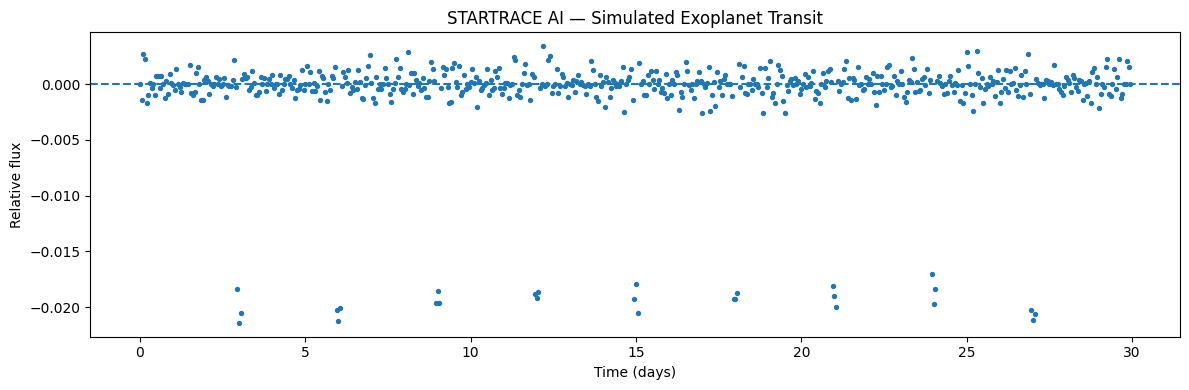

In [31]:

plt.figure(figsize=(12, 4))
plt.scatter(
    processed["time"],
    processed["relative_flux"],
    s=8,
)
plt.axhline(0, linestyle="--")
plt.xlabel("Time (days)")
plt.ylabel("Relative flux")
plt.title("STARTRACE AI — Simulated Exoplanet Transit")
plt.tight_layout()
plt.show()
